In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'NB')
pth_out = os.path.join(pth, 'figures', 'neuroblastoma')

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
adata

AnnData object with n_obs × n_vars = 5101 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident', 'celltype'
    uns: 'Phase_colors', 'X_name', 'celltype_colors', 'ident_colors', 'log1p'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts'

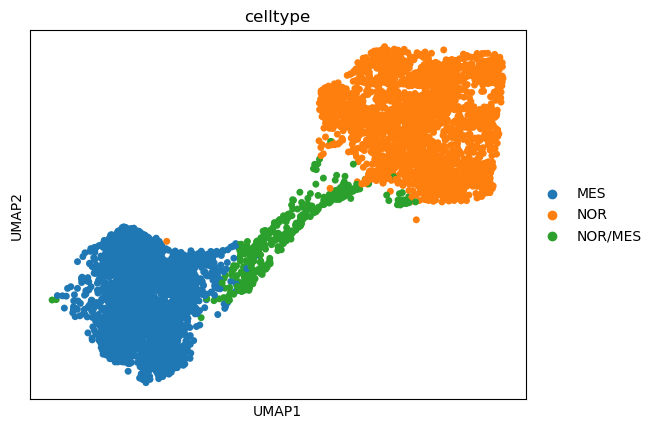

In [4]:
sc.pl.umap(adata, color = 'celltype', size = 100)

inferring a principal curve --> parameters used 
    30 principal points, mu = 100, lambda = 1e-05


    finished (0:00:02) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.


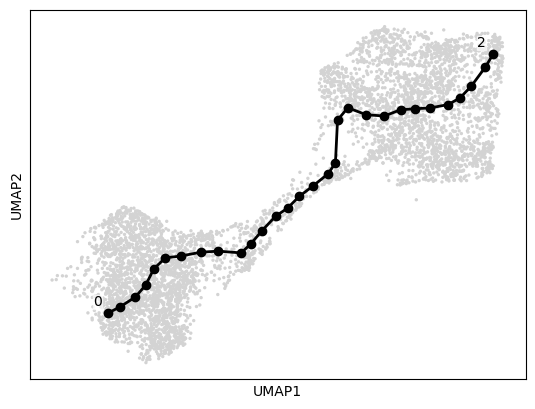

In [5]:
scf.tl.curve(adata, Nodes = 30, epg_lambda = 1e-5, epg_mu = 100, use_rep = 'umap', plot = True, basis = 'umap')

In [6]:
scf.tl.root(adata, 2)

node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [7]:
scf.tl.pseudotime(adata)

projecting cells onto the principal graph


    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


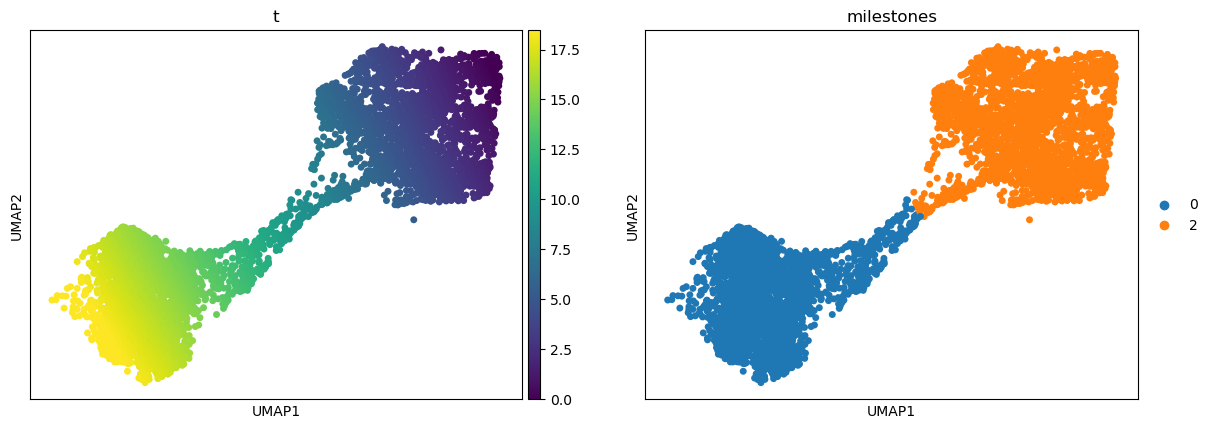

In [8]:
sc.pl.umap(adata, color = ['t', 'milestones'], size = 100)

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


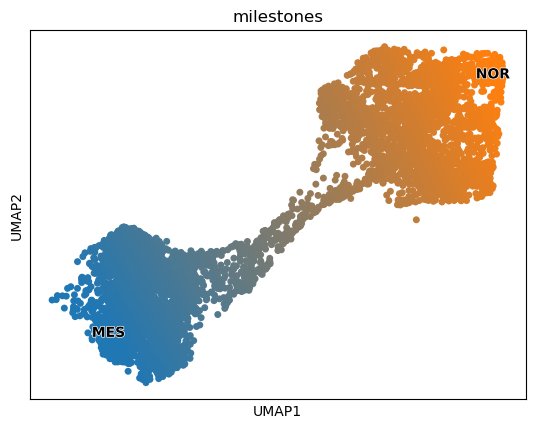

In [9]:
scf.tl.rename_milestones(adata, new = {'0' : 'MES', '2' : 'NOR'})
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 100)

In [ ]:
del adata.uns['epg']
adata.write(os.path.join(pth_in, 'manifold.h5ad'))

/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
  warnings.warn(


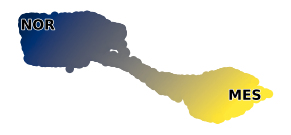

In [ ]:
s = 150
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.umap(adata, color = 't', cmap = 'cividis',
           size = s, colorbar_loc = None,
           frameon = False, show = False, ax = ax)
scf.pl.milestones(adata, basis = 'umap', annotate = True,
                  alpha = 0, show = False, ax = ax)
ax.invert_xaxis(); ax.set_title('')

pos_dict = {
    'NOR' : (-.75, -.25),
    'MES' : (-.5, 1)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'manifold.pdf')
plt.savefig(fn, bbox_inches = 'tight')